In [1]:
#Shriyans Singh 114807762
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

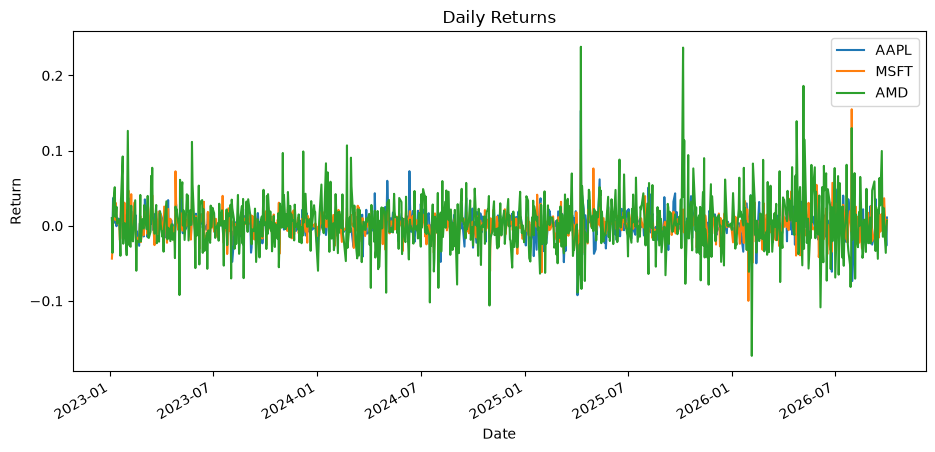

In [2]:
#q1 I used gemini ONLY to figure out how to download the data. I couldn't find it on the nasdaq.com site (it wouldn't let me download) so I had gemini figure out the links to where to download.For q8 i used SPY because that was the best I could find for S&P 500

start="2023-01-03"
end="2026-09-30"#dates so i don't have to keep typing it out every single time

def file_load(filename):
    df=pd.read_csv(filename)
    df["Date"]=pd.to_datetime(df["Date"])
    close=df["Close/Last"].astype(str).str.replace(r"[\$,]","",regex=True).astype(float) #why did they use this as column name idk, it seems kinda weird to add the /Last. got an error without the regex=True. that is new to me
    s=pd.Series(close.values,index=df["Date"])
    return s.sort_index().loc[start:end]

prices=pd.DataFrame({"AAPL":file_load("AAPL.csv"),"MSFT":file_load("MSFT.csv"),"AMD":file_load("AMD.csv")})
returns=prices.pct_change().dropna()
returns.plot(figsize=(11,5))
plt.title("Daily Returns")
plt.ylabel("Return")
plt.show()

#the nasdaq.com prices appear to not be dividend adjusted but they are split-adjusted.(split=change in stock volume)


In [3]:
#q2
annual_avg=252*returns.mean()
annual_std=np.sqrt(252)*returns.std()
print(pd.DataFrame({"Mean":annual_avg,"Std Dev": annual_std}))

          Mean   Std Dev
AAPL  0.296343  0.258112
MSFT  0.238897  0.263350
AMD   0.765228  0.567480


In [4]:
#q3
print(returns.cov()*252)#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.cov.html
print(returns.corr())#https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-corr/

          AAPL      MSFT       AMD
AAPL  0.066622  0.025717  0.043166
MSFT  0.025717  0.069353  0.052224
AMD   0.043166  0.052224  0.322034
          AAPL      MSFT       AMD
AAPL  1.000000  0.378342  0.294702
MSFT  0.378342  1.000000  0.349448
AMD   0.294702  0.349448  1.000000


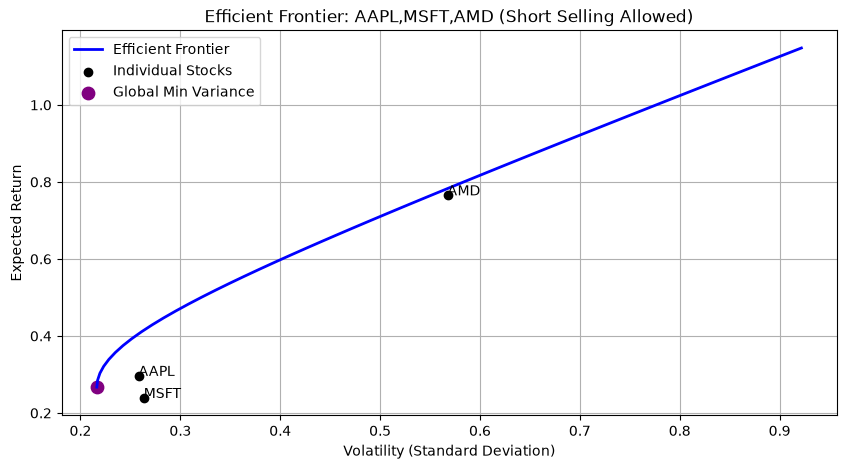

In [5]:
#q4-doesn't state whether short selling is allowed or not so im assuming short selling is allowed
mu=annual_avg.values
Sigma=(252*returns.cov()).values
names=list(returns.columns)
stds=np.sqrt(np.diag(Sigma))#https://www.geeksforgeeks.org/python/numpy-diag-python/

#class 19 to 21 had alot, so im reusing it. 
def global_min_variance_portfolio(Sigma):
    n = Sigma.shape[0]
    Sigma_inv = np.linalg.inv(Sigma)#comp inverse
    ones = np.ones(n)  #vectors of 1s have length n
    w_gmv = Sigma_inv @ ones
    w_gmv /= np.sum(w_gmv)
    return w_gmv


def min_var_portfolio(r, Sigma, target_return):
    n = len(r) #total asset num from legnth of expected
    mu = np.array(r)
    Sigma = np.array(Sigma)
    Sigma_inv = np.linalg.inv(Sigma)
    A = mu @ Sigma_inv @ mu#scalar const
    B = mu @ Sigma_inv @ np.ones(n)
    C = np.ones(n) @ Sigma_inv @ np.ones(n)
    D = A * C - B**2
    lambda1 = (C * target_return - B) / D
    lambda2 = (A - B * target_return) / D
    w = Sigma_inv @ (lambda1 * mu + lambda2 * np.ones(n))
    return w

w_gmv = global_min_variance_portfolio(Sigma)#leftmost point of the frontier is here
r_gmv = mu @ w_gmv
sigma_gmv = np.sqrt(w_gmv @ Sigma @ w_gmv)

# Efficient frontier
target_returns = np.linspace(r_gmv,mu.max()*1.5, 50)
frontier_vols, frontier_rets = [], []
for r_target in target_returns:
    w = min_var_portfolio(mu, Sigma, r_target)
    frontier_rets.append(mu@w)
    frontier_vols.append(np.sqrt(w @ Sigma @ w))

plt.figure(figsize=(10,5))
plt.plot(frontier_vols, frontier_rets, 'b-', lw=2, label='Efficient Frontier')
plt.scatter(stds, mu, color='black',label='Individual Stocks')
plt.title("Efficient Frontier: AAPL,MSFT,AMD (Short Selling Allowed)")
for i,n in enumerate(names):
    plt.annotate(n,(stds[i],mu[i]))
plt.scatter(sigma_gmv, r_gmv, color='purple',s=80,label='Global Min Variance')
plt.xlabel("Volatility (Standard Deviation)")
plt.ylabel("Expected Return")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
#q5
#i choose target return of 40% since thats a fairly reasonable one over time imo and is above the min variance gloabl return- i chose 20% first because it seemed nice but that was too low and wasn't very effcient.
target_return=.4
wq5=min_var_portfolio(mu,Sigma,target_return)
print(pd.Series(wq5,index=names))
print("Sum of weights: ",wq5.sum())
print("Portfolio Return: ",mu@wq5)
print("Portfolio std: ",np.sqrt(wq5@Sigma@wq5))

AAPL    0.507003
MSFT    0.242247
AMD     0.250750
dtype: float64
Sum of weights:  0.9999999999999998
Portfolio Return:  0.3999999999999999
Portfolio std:  0.2551087597234059


Tangency Return:  0.45017986305563934
Tangency STD:  0.28545290350674507
Sharpe Ratio:  1.5070081886396873


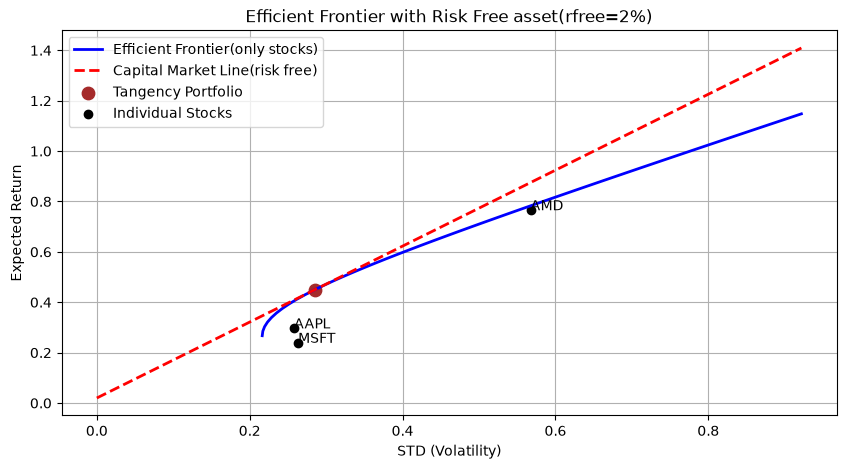

In [7]:
#q6
#from class20
def tangency_portfolio(r, Sigma, rf):
    mu = np.array(r)
    Sigma = np.array(Sigma)
    excess_returns = mu - rf
    Sigma_inv = np.linalg.inv(Sigma)
    w_tan = Sigma_inv @ excess_returns
    w_tan /= np.sum(w_tan)  # Normalize to sum to 1
    return w_tan

rfree=0.02
w_tan=tangency_portfolio(mu,Sigma,rfree)
r_tan=mu@w_tan
sig_tan=np.sqrt(w_tan@Sigma@w_tan)
sharpe=(r_tan-rfree)/sig_tan#slope of line=m in y=mx+b
print("Tangency Return: ",r_tan)
print("Tangency STD: ",sig_tan)
print("Sharpe Ratio: ",sharpe)

sig_cml=np.linspace(0,max(frontier_vols),100)
r_cml=rfree+(sharpe*sig_cml)

plt.figure(figsize=(10,5))
plt.plot(frontier_vols,frontier_rets,'b-',lw=2,label='Efficient Frontier(only stocks)')
plt.plot(sig_cml,r_cml,'r--',lw=2,label='Capital Market Line(risk free)')
plt.scatter(sig_tan,r_tan,color='brown',s=80,label='Tangency Portfolio')
plt.scatter(stds,mu,color='black',label='Individual Stocks')
for i,n in enumerate(names):
    plt.annotate(n,(stds[i],mu[i]))
plt.xlabel("STD (Volatility)")
plt.ylabel("Expected Return")#mispelled as retrun
plt.title("Efficient Frontier with Risk Free asset(rfree=2%)")#like the assigment says
plt.legend()
plt.grid(True)
plt.show()

In [8]:
#q7
targetq7=.07
x=(targetq7-rfree)/(r_tan-rfree)#the ratio invested int the tangency port
w_stocks=x*w_tan#the weights on the aapl,msft, amd
w_rf=1-x #everything eft goes to risk free
print(pd.Series(list(w_stocks)+[w_rf],index=names+["Risk Free"]))
print("Portfolio Return: ",w_stocks@mu+w_rf*rfree)
print("Portfolio STD:",np.sqrt(w_stocks@Sigma@w_stocks))

AAPL         0.058480
MSFT         0.017475
AMD          0.040275
Risk Free    0.883770
dtype: float64
Portfolio Return:  0.07
Portfolio STD: 0.03317832004956317


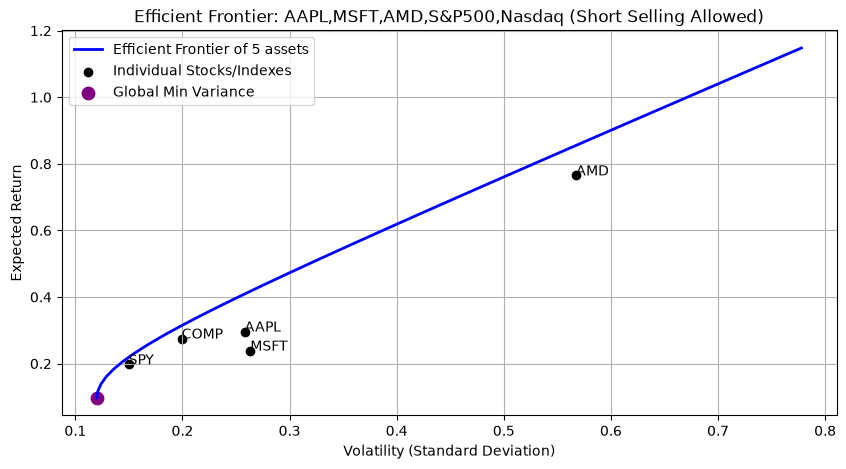

AAPL    0.006170
MSFT    0.112908
AMD    -0.020174
COMP   -1.227595
SPY     2.128691
dtype: float64
Portfolio Return:  0.09662427330209483
Portfolio STD:  0.1200735249576304


In [9]:
#q8 SPY for S&P 500, unlike the nasdaq which has comp there is no direct thing for s&p500 besides spy.
p=pd.DataFrame({"AAPL":file_load("AAPL.csv"),"MSFT":file_load("MSFT.csv"),"AMD":file_load("AMD.csv"),"COMP":file_load("COMP.csv"),"SPY":file_load("SPY.csv")})
res=p.pct_change().dropna()
muq8=252*res.mean().values
Sigmaq8=(252*res.cov()).values
namesq8=list(res.columns)
stdsq8=np.sqrt(np.diag(Sigmaq8))
#glob min var
w_gmvq8=global_min_variance_portfolio(Sigmaq8)
r_gmvq8=muq8@w_gmvq8
sigma_gmvq8=np.sqrt(w_gmvq8@Sigmaq8@w_gmvq8)
#eff fronteir like q4
target_returnsq8 = np.linspace(r_gmvq8,muq8.max()*1.5, 50)
volsq8, retsq8 = [], []
for r_target in target_returnsq8:
    w = min_var_portfolio(muq8, Sigmaq8, r_target)
    retsq8.append(muq8@w)
    volsq8.append(np.sqrt(w @ Sigmaq8 @ w))

plt.figure(figsize=(10,5))
plt.plot(volsq8, retsq8, 'b-', lw=2, label='Efficient Frontier of 5 assets')
plt.scatter(stdsq8, muq8, color='black',label='Individual Stocks/Indexes')
plt.title("Efficient Frontier: AAPL,MSFT,AMD,S&P500,Nasdaq (Short Selling Allowed)")
for i,n in enumerate(namesq8):
    plt.annotate(n,(stdsq8[i],muq8[i]))
plt.scatter(sigma_gmvq8, r_gmvq8, color='purple',s=80,label='Global Min Variance')
plt.xlabel("Volatility (Standard Deviation)")
plt.ylabel("Expected Return")
plt.legend()
plt.grid(True)
plt.show()
#min var with greater exp. return of 7% since its already at greater than 9% so its not binding
print(pd.Series(w_gmvq8,index=namesq8))
print("Portfolio Return: ",r_gmvq8)
print("Portfolio STD: ",sigma_gmvq8)

AAPL    0.462560
MSFT    0.106788
AMD     0.319834
COMP    0.251484
SPY    -0.140667
dtype: float64
Tangency STD  0.2840156999516479
Tangency Return: 0.44870302098423914
Sharpe Ratio:  1.5094342357032497


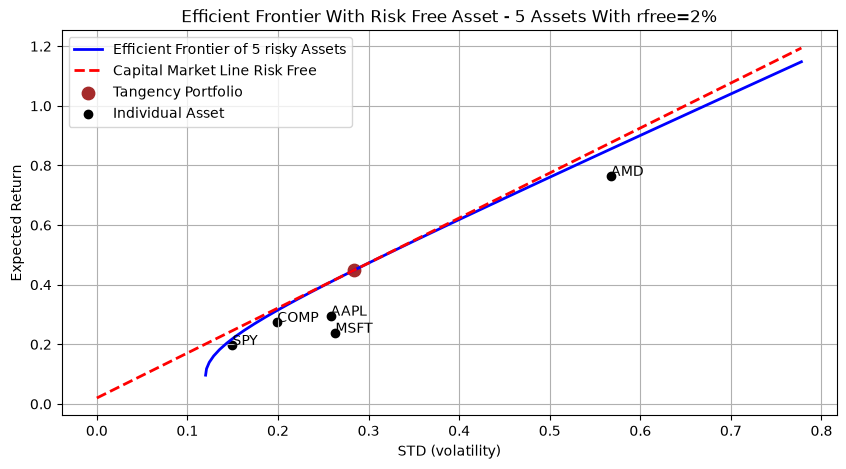

AAPL         0.053949
MSFT         0.012455
AMD          0.037302
COMP         0.029331
SPY         -0.016406
Risk Free    0.883369
dtype: float64
Portfolio Return:  0.07
Portfolio STD: 0.03312499399929462


In [10]:
#q9
w_tanq9=tangency_portfolio(muq8,Sigmaq8,rfree)
r_tanq9=muq8@w_tanq9
sig_tanq9=np.sqrt(w_tanq9@Sigmaq8@w_tanq9)
sharpeq9=((r_tanq9-rfree)/(sig_tanq9))
print(pd.Series(w_tanq9,index=namesq8))
print("Tangency STD ",sig_tanq9)
print("Tangency Return:",r_tanq9)
print("Sharpe Ratio: ",sharpeq9)
#CML cap mark line again
sig_cmlq9=np.linspace(0,max(volsq8),100)
r_cmlq9=(sharpeq9*sig_cmlq9)+rfree #I KEEP PUTING THE ; ARGHHH
plt.figure(figsize=(10,5))#i like this size:D
plt.plot(volsq8,retsq8,'b-',lw=2,label='Efficient Frontier of 5 risky Assets')
plt.plot(sig_cmlq9,r_cmlq9,'r--',lw=2,label='Capital Market Line Risk Free')
plt.scatter(sig_tanq9,r_tanq9,color='brown',s=80,label='Tangency Portfolio')
plt.scatter(stdsq8,muq8,color='black',label='Individual Asset')
for i,n in enumerate(namesq8):
    plt.annotate(n,(stdsq8[i],muq8[i]))
plt.title("Efficient Frontier With Risk Free Asset - 5 Assets With rfree=2%")
plt.xlabel("STD (volatility)")
plt.ylabel("Expected Return")
plt.legend()
plt.grid(True)
plt.show()

target_q9=.07
temp9=((target_q9-rfree)/(r_tanq9-rfree))
w_stocksq9=temp9*w_tanq9
w_rfq9=1-temp9
print(pd.Series(list(w_stocksq9)+[w_rfq9],index=namesq8+["Risk Free"]))
print("Portfolio Return: ",w_stocksq9@muq8+w_rfq9*rfree)
print("Portfolio STD:",np.sqrt(w_stocksq9@Sigmaq8@w_stocksq9))

In [11]:
#q10
#50% nasdaq 50% sp500...
portfolioReturn=(1/2)*(res["SPY"]+res["COMP"])
for stock in ["MSFT","AAPL","AMD"]:
    r=stats.linregress(portfolioReturn,res[stock])
    print(stock)
    print("Slope (beta): ",round(r.slope,4))#sensitivity
    print("Alpha(intercept daily):",round(r.intercept,6))#average return not explained by market
    print("R^2: ",round(r.rvalue**2,4))#r^2 = stock variance explained by market
    print("Alpha T stat: ",round(r.intercept/r.intercept_stderr,3))#alpha t-stat to see if alpha is very different from 0
    print("Beta p val:", r.pvalue)#beta p-val to see if beta is very different from 0


MSFT
Slope (beta):  0.9412
Alpha(intercept daily): 6.5e-05
R^2:  0.3804
Alpha T stat:  0.151
Beta p val: 2.1709793191368614e-99
AAPL
Slope (beta):  0.9365
Alpha(intercept daily): 0.000297
R^2:  0.3921
Alpha T stat:  0.715
Beta p val: 2.928512942035261e-103
AMD
Slope (beta):  2.083
Alpha(intercept daily): 0.001082
R^2:  0.4012
Alpha T stat:  1.193
Beta p val: 2.3778566531854276e-106


In [13]:
#Based on q10 answer I can see:
#AAPL and MSFT beta's are almost the same (approx .94 each) in the 50/50 index portfolio, barely less than the market, 
#while AMD (approx 2.08) moves over twicce as much as the market so it is an agressive stock. 
#the pvalues for all are basically 0 so the betas are statisitaclly significant.
#the alphas dailies are small (AMD has the largest at .001 a day) byt all of them are well below the 2 and none are statiscially differnet.
#the stocks don't signficantly beat what the market exposure predicts by itself.
#r^2 on the other hand is around .38 to .4 for all three of the stocks. this means the market explains around 40% of each stock's 
#daily variance
#the other approximately 60% is from each company itself whcih can be diversifed to deal with it.
#AMD is the most market sensitive and AAPL and MSFT are almost entirely identical to each other,
#and the r^2 is similar among all three.
#
#
#
#
#

In [ ]:
#